# Demanda de Inventario de Grupo Bimbo

## 1. Tiempo y logística

* **`Semana` (Número de semana):** Representa el período de tiempo de la transacción. La semana operativa de Grupo Bimbo comprende desde el jueves hasta el miércoles.
* **`Agencia_ID` (Identificador de agencia):** Identifica el centro de distribución físico donde se cargan los camiones de reparto con productos frescos.
* **`Canal_ID` (Identificador de canal de ventas):** Identifica la categoría del cliente, como pequeñas tiendas de barrio (*tienditas*), grandes supermercados y tiendas de conveniencia.
* **`Ruta_SAK` (Identificador de ruta):** Identifica la ruta geográfica específica que recorre un camión de reparto. Una misma agencia puede tener varias rutas de distribución.

## 2. Entidades

* **`Cliente_ID` y `NombreCliente` (Identificador y nombre del cliente):** Identifican la tienda específica que recibe la entrega, como «Abarrotes La Lupita» o una sucursal de Walmart.
* **`Producto_ID` y `NombreProducto` (Identificador y nombre del producto):** Identifican el producto específico que se entrega, incluyendo su marca, nombre y peso. Por ejemplo, «Pan Blanco Bimbo 680 g».

## 3. Flujo de transacciones

* **`Venta_uni_hoy` (Unidades entregadas esta semana):** Número de unidades de producto que el conductor entrega físicamente a la tienda durante la semana actual.
* **`Venta_hoy` (Ingresos por ventas de esta semana):** Ingresos brutos, expresados en pesos mexicanos, correspondientes a las unidades entregadas a la tienda.
* **`Dev_uni_proxima` (Unidades devueltas la próxima semana):** Número de unidades de la entrega actual que no se vendieron antes de caducar. El conductor recoge estos productos vencidos, conocidos como *merma por caducidad*, durante la entrega de la semana siguiente.
* **`Dev_proxima` (Valor de las devoluciones de la próxima semana):** Valor monetario, expresado en pesos mexicanos, reembolsado o acreditado a la tienda por las unidades devueltas debido a su caducidad.

## 4. Variable objetivo: `Demanda_uni_equil`

La **demanda ajustada** es la variable objetivo que se busca predecir. Representa una estimación de la demanda del consumidor final: la cantidad de unidades de producto que los consumidores realmente compraron, en lugar de limitarse a contar las unidades entregadas a una tienda.

La variable objetivo se calcula mediante la siguiente fórmula:

$$
\text{Demanda\_uni\_equil} =
\max(0,\ \text{Venta\_uni\_hoy} - \text{Dev\_uni\_proxima})
$$

Donde:

* `Venta_uni_hoy`: Unidades entregadas durante la semana actual.
* `Dev_uni_proxima`: Unidades de esa entrega que se devuelven durante la semana siguiente.
* `max(0, ...)`: Garantiza que la demanda ajustada no sea negativa.


In [26]:
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np
import copy
import os
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [27]:
print(os.getcwd())

C:\Users\alexi\OneDrive\Escritorio\Personal\Proyecto_DL\backend\ai


In [52]:
dtypes = { #se trata de bajar la memoria de los datos para mejorar la lectura de datos 
    'Semana': 'int8',
    'Agencia_ID': 'int16',
    'Canal_ID': 'int8',
    'Ruta_SAK': 'int32',
    'Cliente_ID': 'int32',
    'Producto_ID': 'int32',
    'Venta_uni_hoy': 'int32',
    'Venta_hoy': 'float32',
    'Dev_uni_proxima': 'int32',
    'Dev_proxima': 'float32',
    'Demanda_uni_equil': 'int32'
}

productos = pd.read_csv("../data/raw/producto_tabla.csv") 
clientes = pd.read_csv("../data/raw/cliente_tabla.csv")

df = pd.read_csv("../data/raw/train.csv", dtype=dtypes, nrows=1_000_000) #nrows=3_000_000) #May change | skiprows=range(1, 50_000_001),
df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
0,3,1110,7,3301,15766,1212,3,25.139999,0,0.0,3
1,3,1110,7,3301,15766,1216,4,33.520000,0,0.0,4
2,3,1110,7,3301,15766,1238,4,39.320000,0,0.0,4
3,3,1110,7,3301,15766,1240,4,33.520000,0,0.0,4
4,3,1110,7,3301,15766,1242,3,22.920000,0,0.0,3


In [53]:
#df.to_csv("train_sample_2.csv", index= False)
productos.head()

,Producto_ID,NombreProducto
0,0,NO IDENTIFICADO 0
1,9,Capuccino Moka 750g NES 9
2,41,Bimbollos Ext sAjonjoli 6p 480g BIM 41
3,53,Burritos Sincro 170g CU LON 53
4,72,Div Tira Mini Doradita 4p 45g TR 72


In [54]:
clientes.head()

,Cliente_ID,NombreCliente
0,0,SIN NOMBRE
1,1,OXXO XINANTECATL
2,2,SIN NOMBRE
3,3,EL MORENO
4,4,SDN SER DE ALIM CUERPO SA CIA DE INT


In [55]:
print(f" Duplicados en productos: {productos.duplicated(keep='first').sum()}")
clientesNombre = clientes['NombreCliente']
print(f" Duplicados en productos: {clientesNombre.duplicated(keep=False).sum()}")

 Duplicados en productos: 0
 Duplicados en productos: 659535


In [34]:
print('cantidad de observaciones (clientes): ',df.shape[0])
print('cantidad de variables: ',df.shape[1])
print(df.shape)

cantidad de observaciones (clientes):  1000000
cantidad de variables:  11
(1000000, 11)


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   Semana             1000000 non-null  int8   
 1   Agencia_ID         1000000 non-null  int16  
 2   Canal_ID           1000000 non-null  int8   
 3   Ruta_SAK           1000000 non-null  int32  
 4   Cliente_ID         1000000 non-null  int32  
 5   Producto_ID        1000000 non-null  int32  
 6   Venta_uni_hoy      1000000 non-null  int32  
 7   Venta_hoy          1000000 non-null  float32
 8   Dev_uni_proxima    1000000 non-null  int32  
 9   Dev_proxima        1000000 non-null  float32
 10  Demanda_uni_equil  1000000 non-null  int32  
dtypes: float32(2), int16(1), int32(6), int8(2)
memory usage: 34.3 MB


In [36]:
df.describe()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
count,1000000.0,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,3.0,1119.880522,1.066424,1588.443300,1.344409e+06,13566.496539,6.646702,70.972176,0.089440,1.084095,6.580689
std,0.0,4.943890,0.590644,833.859215,1.492811e+06,17223.695381,17.139278,287.965302,1.770789,20.257387,17.016226
min,3.0,1110.000000,1.000000,1.000000,3.967000e+03,72.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.0,1117.000000,1.000000,1096.000000,2.334990e+05,1216.000000,2.000000,18.980000,0.000000,0.000000,2.000000
50%,3.0,1120.000000,1.000000,1423.000000,7.010680e+05,1284.000000,4.000000,34.590000,0.000000,0.000000,4.000000
75%,3.0,1123.000000,1.000000,1603.000000,2.005360e+06,32322.000000,7.000000,63.360001,0.000000,0.000000,7.000000
max,3.0,1130.000000,11.000000,4501.000000,1.000000e+08,49994.000000,2000.000000,31809.599609,1008.000000,9426.000000,2000.000000


In [37]:
df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
0,3,1110,7,3301,15766,1212,3,25.139999,0,0.0,3
1,3,1110,7,3301,15766,1216,4,33.520000,0,0.0,4
2,3,1110,7,3301,15766,1238,4,39.320000,0,0.0,4
3,3,1110,7,3301,15766,1240,4,33.520000,0,0.0,4
4,3,1110,7,3301,15766,1242,3,22.920000,0,0.0,3


In [38]:
###
###
for colu in df.columns:
    cantidad = df[colu].value_counts()
    #print(f"Nombre de Columna {colu}: Tiene {cantidad} valores.\n----")
    print(f"{cantidad} \n-------" )

Semana
3    1000000
Name: count, dtype: int64 
-------
Agencia_ID
1123    111015
1126     87708
1117     84704
1121     79468
1116     75938
1120     70134
1122     67506
1111     67346
1127     64057
1119     62562
1124     53715
1112     52795
1118     52707
1113     30859
1130     17029
1110      8014
1129      7355
1114      7088
Name: count, dtype: int64 
-------
Canal_ID
1     977267
2      14443
7       6931
11       662
8        421
4        276
Name: count, dtype: int64 
-------
Ruta_SAK
1415    6657
1401    6480
1412    6447
1414    6218
1404    6211
        ... 
125       22
75        19
19        19
3407      13
600        4
Name: count, Length: 613, dtype: int64 
-------
Cliente_ID
17851      125
19174      118
22861      118
17815      115
22533      114
          ... 
1262149      1
1230049      1
2317525      1
2353821      1
2217708      1
Name: count, Length: 58794, dtype: int64 
-------
Producto_ID
2233     34320
1278     34295
1250     33761
1240     31487
35651    

In [39]:
#Variables categoricas:
varCatNominal = ['Semana', 'Agencia_ID', 'Canal_ID' 'Ruta_SAK']
# Cliente_ID y Producto_ID tambien son categoricas nominales, 
#pero por la cantidad de datos no se procesaran, se usaran otros metodos.

#varCatOrdinal = []

#Variables Numericas:
varNumericas = ["Venta_uni_hoy", "Venta_hoy","Dev_uni_proxima", "Dev_proxima", "Demanda_uni_equil"]

In [40]:
df.columns

Index(['Semana', 'Agencia_ID', 'Canal_ID', 'Ruta_SAK', 'Cliente_ID',
       'Producto_ID', 'Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima',
       'Dev_proxima', 'Demanda_uni_equil'],
      dtype='object')

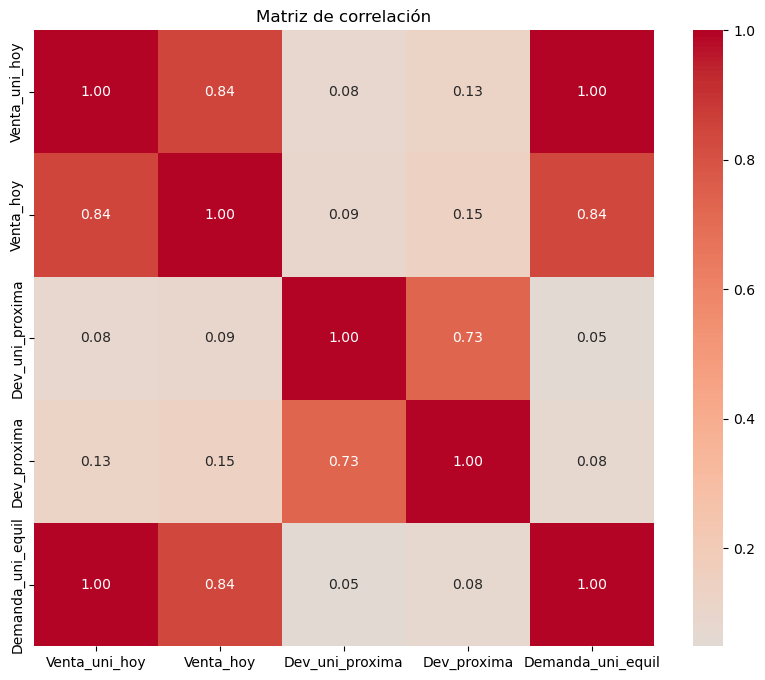

In [41]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[varNumericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()